# Active Subspaces of a Coupled Fire Detection Satellite Model

From: Likelihood-Based Approach to Multidisciplinary Analysis Under Uncertainty

__Shankar Sankararaman__, Department of Civil and Environmental Engineering, Vanderbilt University, Nashville, TN

__Sankaran Mahadevan__, Department of Civil and Environmental Engineering, Vanderbilt University, Nashville, TN

Notebook: Claude (Anthropic) for P. Constantine, 2026

### Summary

Sankararaman and Mahadevan [[1]](#refs) propagate uncertainty through a three-discipline conceptual design model of a forest-fire-monitoring satellite (orbit, attitude control and power, with feedback coupling between the last two) that has nine normal inputs and three outputs: total torque $\tau_{tot}$, total power $P_{tot}$ and solar array area $A_{sa}$. We reimplement the model in numpy, solve the coupled fixed point to a relative tolerance of $10^{-13}$, compute exact gradients by the complex step, and estimate an active subspace for each output from 2000 samples. All three outputs have a dominant one-dimensional active subspace; the total torque, which depends on the product of the aerodynamic moment arm and the drag coefficient, is better described in two dimensions.

### Active subspaces in brief

For a scalar function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the matrix $\mathbf C = \int \nabla f\,\nabla f^T \rho\, d\mathbf x = \mathbf W \Lambda \mathbf W^T$ measures how $f$ changes, on average, along each direction. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the span of the first $n$ eigenvectors $\mathbf W_1$, and $f(\mathbf x) \approx g(\mathbf W_1^T\mathbf x)$ for some function $g$ of the $n$ active variables $\mathbf y = \mathbf W_1^T\mathbf x$. $\mathbf C$ is estimated by Monte Carlo from gradient samples, the bootstrap measures the uncertainty in the estimate, and a sufficient summary plot of $f$ against $\mathbf y$ shows whether the reduced description holds. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

The satellite (Sec. 6.1 of [[1]](#refs), after Wertz and Larson [[2]](#refs) and Ferson et al. [[3]](#refs)) has three subsystems. `fire_satellite_model.py` implements Eqs. (11)–(33) of [[1]](#refs) with the constants of its Table 1.

**Orbit** (altitude $H$): with $R = R_E + H$,
$$v = \sqrt{\mu/R},\quad \Delta t_{orbit} = 2\pi R/v,\quad \Delta t_{eclipse} = \frac{\Delta t_{orbit}}{\pi}\arcsin\frac{R_E}{R},\quad \theta_{slew} = \arctan\frac{\sin(\phi_{target}/R_E)}{1-\cos(\phi_{target}/R_E) + H/R_E}.$$

**Attitude control** (needs $I_{max}, I_{min}$ from the power subsystem):
$$\tau_{tot} = \max(\tau_{slew}, \tau_{dist}),\quad \tau_{slew} = \frac{4\theta_{slew}}{\Delta t_{slew}^2} I_{max},\quad \tau_{dist} = \sqrt{\tau_g^2 + \tau_{sp}^2 + \tau_m^2 + \tau_a^2},$$
$$\tau_g = \frac{3\mu}{2R^3}|I_{max}-I_{min}|\sin 2\theta,\quad \tau_{sp} = L_{sp}\frac{F_s}{c}A_s(1+q)\cos i,\quad \tau_m = \frac{2 M R_D}{R^3},\quad \tau_a = \tfrac12 L_a \rho C_d A v^2,$$
$$P_{ACS} = \tau_{tot}\,\omega_{max} + n P_{hold}.$$

**Power** (needs $P_{ACS}$): $P_{tot} = P_{ACS} + P_{other}$; with $T_e = \Delta t_{eclipse}$, $T_d = \Delta t_{orbit} - T_e$,
$$P_{sa} = \frac{P_{tot}T_e/0.6 + P_{tot}T_d/0.8}{T_d},\quad P_{EOL} = \eta F_s I_d \cos i\,(1-\epsilon_{deg})^{LT},\quad A_{sa} = P_{sa}/P_{EOL},$$
and the solar array length, width and mass $L = \sqrt{A_{sa}r_{lw}/n_{sa}}$, $W = \sqrt{A_{sa}/(r_{lw}n_{sa})}$, $m_{sa} = 2\rho_{sa}LWt$ give the array moments of inertia (Eqs. 28–30), which are added to the body's to give $I_{max}$ and $I_{min}$ (Eqs. 31–33).

The feedback $P_{ACS} \to (I_{max}, I_{min}) \to P_{ACS}$ is solved by fixed-point iteration on $P_{ACS}$, starting from $P_{ACS} = nP_{hold}$, until successive iterates agree to a relative $10^{-13}$.

**Quantities of interest** (Sec. 6.3): total torque $\tau_{tot}$ (N m), total power $P_{tot}$ (W) and solar array area $A_{sa}$ (m²).

**Choices where the printed paper is ambiguous** (details in `DATA.md`):
- $\omega_{max} = 6000$ rpm is converted to rad/s. This reproduces the paper's Fig. 11 ($P_{ACS}$ peaks near 67 W); the OpenTURNS use case [[4]](#refs) uses 6000 as rad/s, which gives about 130 W.
- Eq. (27) prints $m_{sa}$ (the array mass, defined from $L$ and $W$) under the square roots for $L$ and $W$; we use $n_{sa}$, the number of arrays, as OpenTURNS does.
- $\epsilon_{deg} = 0.0375$ ("% per year" in Table 1) is used as the fraction 0.0375 per year.
- $\theta$ and $i$ are in degrees and converted to radians.

**Inputs.** The paper (Table 2, Sec. 6.2) treats the nine inputs as independent normals. We use the paper's means and standard deviations, truncated to the bounds of the OpenTURNS use case [[4]](#refs) (mean $\pm$ 3 sd for eight inputs; $[0.2, 0.8]$ for the reflectance factor $q$) so that all inputs stay physical. The paper prints a standard deviation of 1 for $q$; OpenTURNS has 0.1. We follow the paper and check the other value below. The table is built from the model code.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
import active_subspaces as ac
import fire_satellite_model as fm

SEED = 2012   # every rng= below uses this seed
t_start = time.perf_counter()

labels = [r'$H$', r'$P_{other}$', r'$F_s$', r'$\theta$', r'$L_{sp}$', r'$q$', r'$R_D$', r'$L_a$', r'$C_d$']
qoi_labels = [r'$\tau_{tot}$ (N m)', r'$P_{tot}$ (W)', r'$A_{sa}$ (m$^2$)']
desc = ['Altitude', 'Power other than ACS', 'Average solar flux', 'Deviation of moment axis',
        'Moment arm, radiation torque', 'Reflectance factor', 'Residual dipole',
        'Moment arm, aerodynamic torque', 'Drag coefficient']
print(f"{'input':8s} {'description':32s} {'unit':7s} {'mean':>9s} {'sd':>8s} {'lower':>9s} {'upper':>9s}")
for j, name in enumerate(fm.NAMES):
    print(f'{name:8s} {desc[j]:32s} {fm.UNITS[j]:7s} {fm.MEAN[j]:9.4g} {fm.SD[j]:8.3g} '
          f'{fm.LOWER[j]:9.4g} {fm.UPPER[j]:9.4g}')

input    description                      unit         mean       sd     lower     upper
H        Altitude                         m         1.8e+07    1e+06   1.5e+07   2.1e+07
P_other  Power other than ACS             W            1000       50       850      1150
F_s      Average solar flux               W/m^2        1400       20      1340      1460
theta    Deviation of moment axis         deg            15        1        12        18
L_sp     Moment arm, radiation torque     m               2      0.4       0.8       3.2
q        Reflectance factor               -             0.5        1       0.2       0.8
R_D      Residual dipole                  A m^2           5        1         2         8
L_a      Moment arm, aerodynamic torque   m               2      0.4       0.8       3.2
C_d      Drag coefficient                 -               1      0.3       0.1       1.9


### Load the data

`generate_data.py` drew 2000 samples from the truncated normals (seed 2012), solved the coupled system, and computed the gradients of the three outputs with respect to the physical inputs by the complex step carried through the fixed-point iteration (`DATA.md`; the run takes under a second).

In [2]:
X = np.loadtxt('inputs.csv', delimiter=',')                          # (2000, 9) physical inputs
F = np.loadtxt('outputs.csv', delimiter=',')                         # (2000, 3) tau_tot, P_tot, A_sa
G = np.loadtxt('gradients.csv', delimiter=',').reshape(len(X), 3, 9)  # d(output)/d(physical input)
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}')

inputs (2000, 9), outputs (2000, 3), gradients (2000, 3, 9)


A check that the model reproduces the stored data, that the fixed-point iteration converges, and that the complex-step gradients agree with central finite differences. The coupling is weak: the derivative of one fixed-point sweep with respect to $P_{ACS}$ (the contraction factor) is computed by the complex step at the mean inputs.

In [3]:
rows = np.arange(5)
F5, info = fm.solve(X, full=True)
print(f'model vs outputs.csv: max relative difference {np.max(np.abs(F5 - F) / np.abs(F)):.1e}; '
      f'{info["iterations"]} fixed-point sweeps; tau_slew > tau_dist at {np.sum(info["tau_slew"] > info["tau_dist"])} samples')

# contraction factor dP_ACS^(k+1)/dP_ACS^(k) at the mean inputs
x = {n: np.array([v], dtype=complex) for n, v in zip(fm.NAMES, fm.MEAN)}
orb = fm.orbit(x['H'])
info0 = fm.solve(fm.MEAN, full=True)[1]
P_star = info0['P_ACS']
print(f'at the mean inputs tau_a / tau_dist = {info0["tau_a"][0] / info0["tau_dist"][0]:.4%}; '
      f'over the samples min tau_a / tau_dist = {np.min(info["tau_a"] / info["tau_dist"]):.3f}')
pw = fm.power(x, P_star + 1e-30j, orb)
rate = fm.attitude(x, pw['I_max'], pw['I_min'], orb)['P_ACS'].imag[0] / 1e-30
print(f'P_ACS at the mean inputs {P_star[0]:.4f} W; contraction factor {rate:.1e}')
F_loose = fm.qoi(X, tol=1e-3)
print(f'outputs at the OpenTURNS tolerance 1e-3 vs 1e-13: max relative difference '
      f'{np.max(np.abs(F_loose - F) / np.abs(F)):.1e}')

# central differences, step 1e-4 sd, on 20 samples
Xc = X[:20]
Gfd = np.empty((20, 3, 9))
for j in range(9):
    dx = np.zeros(9)
    dx[j] = 1e-4 * fm.SD[j]
    Gfd[:, :, j] = (fm.qoi(Xc + dx, tol=1e-15) - fm.qoi(Xc - dx, tol=1e-15)) / (2 * dx[j])
rel = np.linalg.norm(Gfd - G[:20], axis=2) / np.linalg.norm(G[:20], axis=2)
print('central differences vs stored gradients, max relative error (tau_tot, P_tot, A_sa):',
      ', '.join(f'{r:.1e}' for r in rel.max(0)))

model vs outputs.csv: max relative difference 0.0e+00; 3 fixed-point sweeps; tau_slew > tau_dist at 0 samples
at the mean inputs tau_a / tau_dist = 99.9858%; over the samples min tau_a / tau_dist = 0.991
P_ACS at the mean inputs 67.3260 W; contraction factor -1.7e-10
outputs at the OpenTURNS tolerance 1e-3 vs 1e-13: max relative difference 1.5e-16
central differences vs stored gradients, max relative error (tau_tot, P_tot, A_sa): 1.1e-11, 5.4e-10, 9.0e-10


### Estimate the active subspaces

The gradients are exact to rounding error, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1N\sum_i \nabla f(\mathbf x_i)\nabla f(\mathbf x_i)^T$, with 500 bootstrap replicates.

**Normalization.** The input space is `ac.Gaussian(MEAN, SD**2)`: its normalization is $x_j = (\xi_j - \mu_j)/\sigma_j$ with the paper's means and standard deviations, and v1 maps the physical gradients to $\partial f/\partial x_j = \sigma_j\,\partial f/\partial \xi_j$. The samples are drawn from the *truncated* normals, so $\hat{\mathbf C}$ estimates $\mathbf C$ under the truncated density in these coordinates. The approximation is in the space object only: v1 treats the density as the untruncated normal (the normalized inputs are not $N(0, I)$; for $q$, with sd 1 and bounds $[0.2, 0.8]$, they lie in $[-0.3, 0.3]$). Nothing below samples from the space, so this affects only the scaling of the coordinates, not the estimate.

We orient each $\mathbf w_1$ (and $\mathbf w_2$ for $\tau_{tot}$) so that the output increases along it.

In [4]:
space = ac.Gaussian(fm.MEAN, fm.SD**2, names=list(fm.NAMES))
subs = []
for i, q in enumerate(fm.QOI_NAMES):
    sub = ac.active_subspace(space=space, X=X, f=F[:, i], grads=G[:, i], estimator='as',
                             nboot=500, bootstrap_vectors=2, rng=SEED, qoi=q)
    sub = ac.orient(sub, by='covariance', X=X, f=F[:, i], columns=2)
    subs.append(sub)


def top(w, k=4):
    return ', '.join(f'{fm.NAMES[j]} {w[j]:+.3f}' for j in np.argsort(-np.abs(w))[:k])


for i, (q, sub) in enumerate(zip(fm.QOI_NAMES, subs)):
    lam = sub.eigenvalues
    print(f'{q}: n = {sub.n} (eigenvalue-gap rule); lambda_1..4 = '
          + ', '.join(f'{v:.3e}' for v in lam[:4])
          + f'; lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.1f}')
    d = sub.bootstrap_distances.mean(0)
    lo, hi = np.percentile(sub.bootstrap_eigenvalues[:, 0], [2.5, 97.5])
    print(f'    lambda_1 bootstrap 95% interval [{lo:.3e}, {hi:.3e}]; '
          f'mean bootstrap subspace distance n = 1: {d[0]:.1e}, n = 2: {d[1]:.1e}')
    print(f'    w1: {top(sub.W[:, 0])}')
    print(f'    w2: {top(sub.W[:, 1])}')

/tmp/ipykernel_942/2818658073.py:4: AccuracyWarning: bootstrap eigenvector replicates are poorly aligned with the full-sample vectors (columns [1]); their components are ill-defined, e.g. near repeated eigenvalues [accuracy.unaligned_replicates]
  sub = ac.active_subspace(space=space, X=X, f=F[:, i], grads=G[:, i], estimator='as',


tau_tot: n = 1 (eigenvalue-gap rule); lambda_1..4 = 1.847e-05, 5.081e-07, 7.030e-09, 2.659e-12; lambda_1/lambda_2 = 36.3, lambda_2/lambda_3 = 72.3
    lambda_1 bootstrap 95% interval [1.818e-05, 1.875e-05]; mean bootstrap subspace distance n = 1: 3.0e-03, n = 2: 2.5e-03
    w1: C_d +0.827, L_a +0.550, H -0.116, q +0.001
    w2: L_a -0.823, C_d +0.560, H +0.093, q +0.001
P_tot: n = 1 (eigenvalue-gap rule); lambda_1..4 = 2.507e+03, 2.061e-01, 2.006e-01, 3.264e-04; lambda_1/lambda_2 = 12162.0, lambda_2/lambda_3 = 1.0
    lambda_1 bootstrap 95% interval [2.507e+03, 2.507e+03]; mean bootstrap subspace distance n = 1: 2.6e-04, n = 2: 4.6e-01
    w1: P_other +0.999, C_d +0.044, L_a +0.029, H -0.006
    w2: C_d +0.802, L_a +0.551, H -0.224, P_other -0.053
A_sa: n = 1 (eigenvalue-gap rule); lambda_1..4 = 3.056e-01, 6.494e-05, 3.196e-05, 2.210e-05; lambda_1/lambda_2 = 4705.1, lambda_2/lambda_3 = 2.0
    lambda_1 bootstrap 95% interval [3.051e-01, 3.060e-01]; mean bootstrap subspace distance n = 

### Results

#### Total torque $\tau_{tot}$

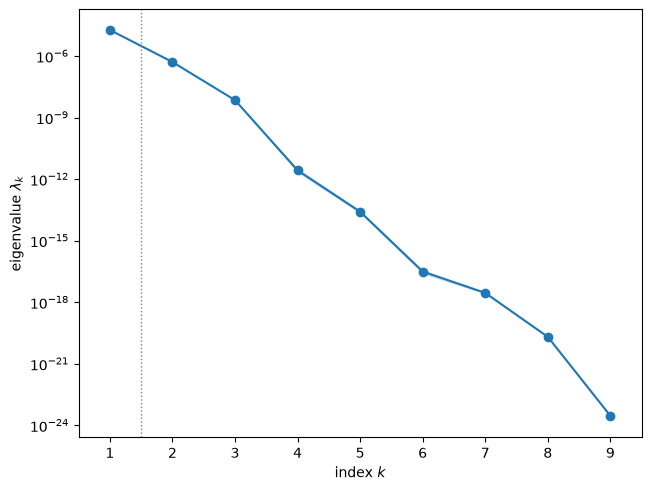

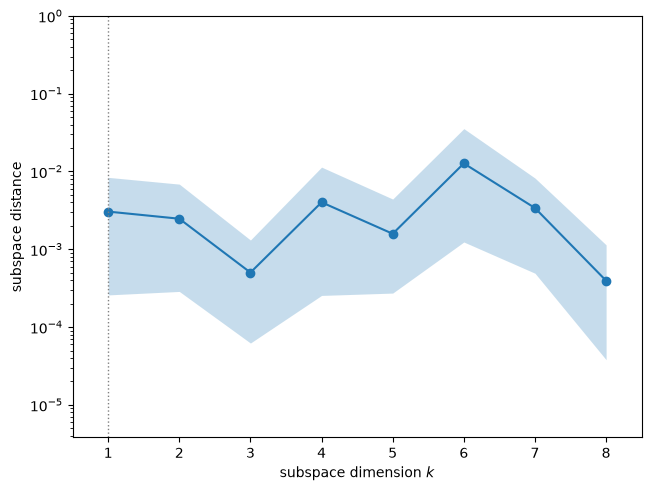

In [5]:
sub = subs[0]
display(ac.plotting.plot_eigenvalues(sub)[0])
display(ac.plotting.plot_subspace_errors(sub)[0])

The first two eigenvalues of $\hat{\mathbf C}$ for $\tau_{tot}$ are $1.847\times10^{-5}$ and $5.081\times10^{-7}$ ($\lambda_1/\lambda_2 = 36.3$), and the third is smaller again by a factor of 72.3; the remaining six are below $3\times10^{-12}$, because the torque does not depend appreciably on six of the nine inputs. The eigenvalue-gap rule picks $n = 1$, and the bootstrap 95% interval for $\lambda_1$ is $[1.818, 1.875]\times10^{-5}$. The mean bootstrap subspace distance is $3.0\times10^{-3}$ for $n = 1$ and $2.5\times10^{-3}$ for $n = 2$, so both the one- and two-dimensional subspaces are well estimated.

gradient direction of log(tau_a) at the mean: H -0.113, L_a +0.551, C_d +0.827; |w1 . ref| = 1.0000


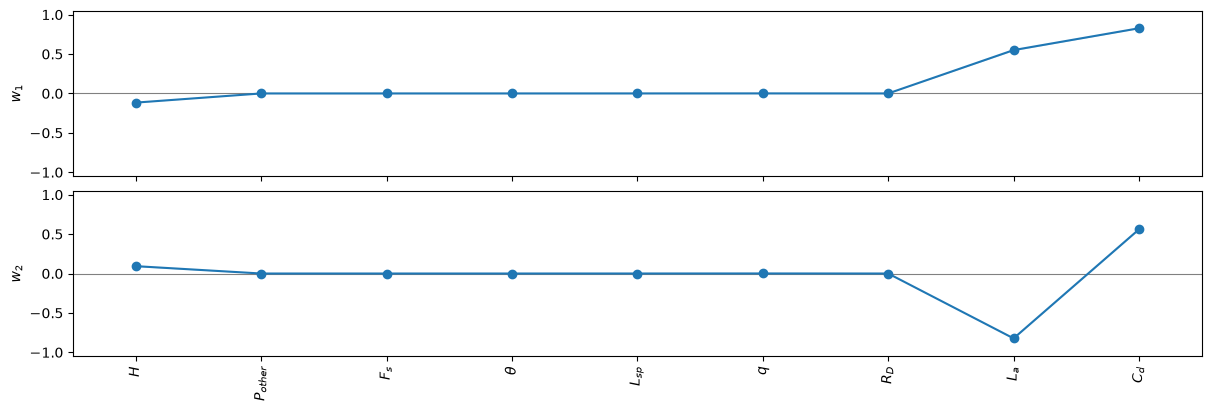

In [6]:
# tau_tot ~ tau_a = L_a rho C_d A v^2 / 2 with v^2 = mu / (R_E + H): its logarithm is linear in
# (L_a, C_d, H) near the mean, with normalized slopes sd/mean (and -sd_H/(R_E + H))
ref = np.zeros(9)
ref[[0, 7, 8]] = [-fm.SD[0] / (fm.RE + fm.MEAN[0]), fm.SD[7] / fm.MEAN[7], fm.SD[8] / fm.MEAN[8]]
ref /= np.linalg.norm(ref)
print(f'gradient direction of log(tau_a) at the mean: H {ref[0]:+.3f}, L_a {ref[7]:+.3f}, C_d {ref[8]:+.3f}; '
      f'|w1 . ref| = {abs(sub.W[:, 0] @ ref):.4f}')
fig, _ = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, interval='percentile', figsize=(12, 4))
fig

The first eigenvector weights the drag coefficient $C_d$ (+0.827) and the aerodynamic moment arm $L_a$ (+0.550), with a small negative weight on the altitude $H$ (−0.116); every other component is at most 0.001 in magnitude. The aerodynamic torque $\tau_a = \tfrac12 L_a\rho C_d A\mu/(R_E+H)$ is 99.99% of $\tau_{dist}$ at the mean inputs, and $\tau_{tot} = \tau_{dist}$ at all 2000 samples, so $\log\tau_{tot}$ is close to linear in $(L_a, C_d, H)$; the gradient direction of $\log\tau_a$ at the mean, $(-0.113, 0.551, 0.827)$, agrees with $\mathbf w_1$ to $|\mathbf w_1\cdot\text{ref}| = 1.0000$. The second eigenvector is the orthogonal combination of the same inputs ($L_a$ −0.823, $C_d$ +0.560, $H$ +0.093): it is there because the product $L_aC_d$ is not a function of one linear combination of $L_a$ and $C_d$.

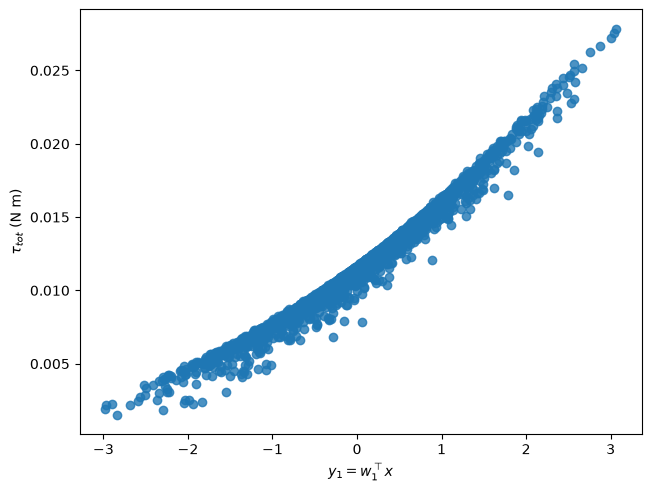

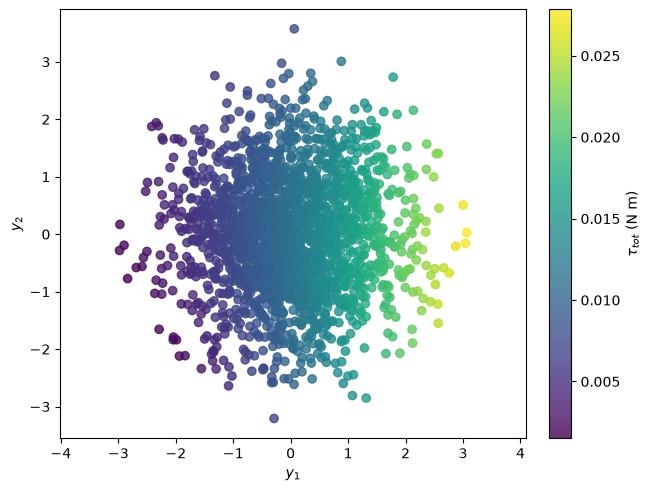

In [7]:
display(ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, 0], dims=1, qoi_label=qoi_labels[0])[0])
display(ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 2), X=X, f=F[:, 0], dims=2,
                                            qoi_label=qoi_labels[0])[0])

The one-dimensional summary plot shows a tight, convex trend of $\tau_{tot}$ against $y_1$, with a visible spread at fixed $y_1$; the two-dimensional plot shows that the remaining variation is along $y_2$. The surrogates below quantify this: a quadratic in $y_1$ has a leave-one-out $R^2$ of 0.98313, and a quadratic in $(y_1, y_2)$ 0.99963.

#### Total power $P_{tot}$

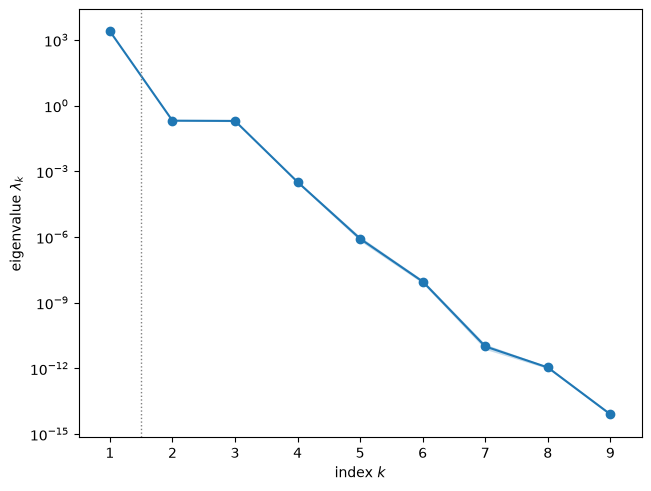

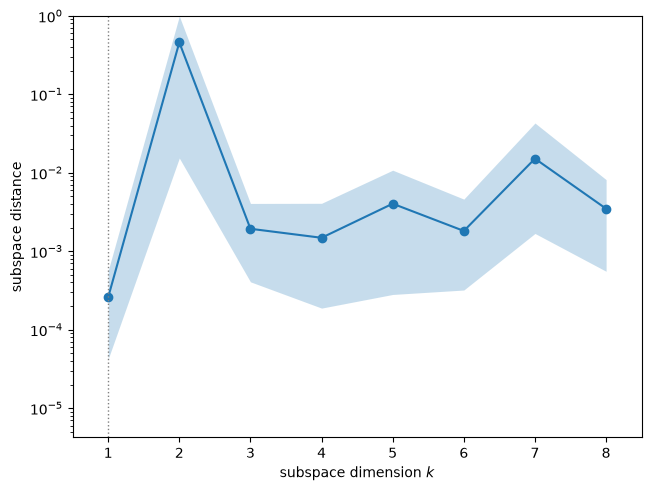

In [8]:
sub = subs[1]
display(ac.plotting.plot_eigenvalues(sub)[0])
display(ac.plotting.plot_subspace_errors(sub)[0])

For $P_{tot}$ the gap is much larger: $\lambda_1 = 2.507\times10^{3}$ and $\lambda_2 = 0.2061$, so $\lambda_1/\lambda_2 = 12162$, and the rule picks $n = 1$ with a mean bootstrap subspace distance of $2.6\times10^{-4}$. The second and third eigenvalues are nearly equal (0.2061 and 0.2006, ratio 1.0), so the second eigenvector is not well determined: its mean bootstrap distance for $n = 2$ is 0.46, and v1 warns that the bootstrap replicates of $\mathbf w_2$ are poorly aligned. This does not affect the one-dimensional subspace.

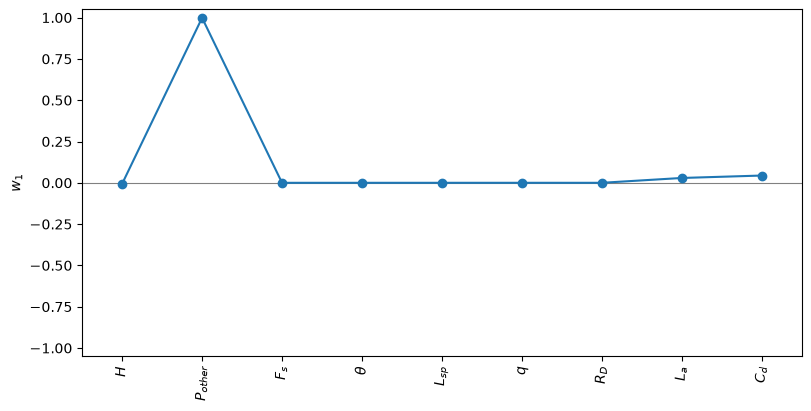

In [9]:
fig, _ = ac.plotting.plot_eigenvectors(sub, indices=[0], labels=labels, interval='percentile', figsize=(8, 4))
fig

The first eigenvector is almost entirely the non-ACS power $P_{other}$ (+0.999), with small weights on $C_d$ (+0.044) and $L_a$ (+0.029) through the attitude-control power $P_{ACS} = \tau_{tot}\,\omega_{max} + nP_{hold}$. This is what the model says: $P_{tot} = P_{other} + P_{ACS}$, and $P_{ACS}$ varies by a few watts (sd 2.64 W below) against 50 W for $P_{other}$.

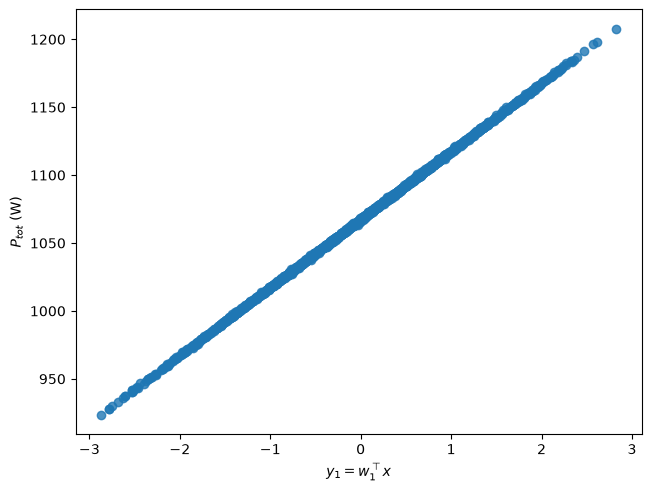

In [10]:
fig, _ = ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, 1], dims=1, qoi_label=qoi_labels[1])
fig

The summary plot of $P_{tot}$ against $y_1$ is a straight line, and a linear function of $y_1$ has a leave-one-out $R^2$ of 0.99992. This output is a one-dimensional, nearly linear function of the inputs.

#### Solar array area $A_{sa}$

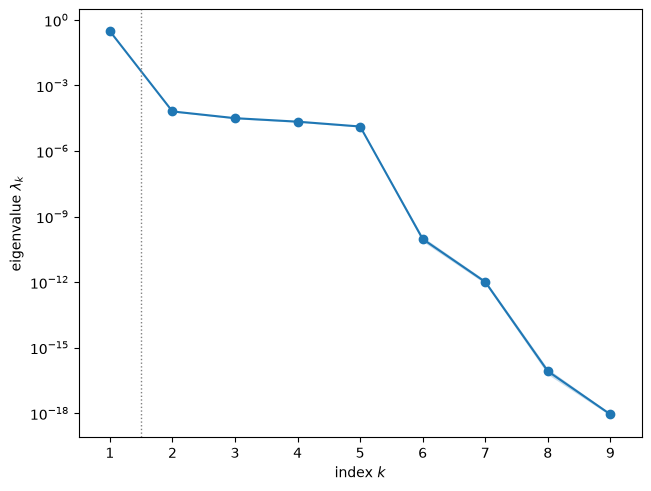

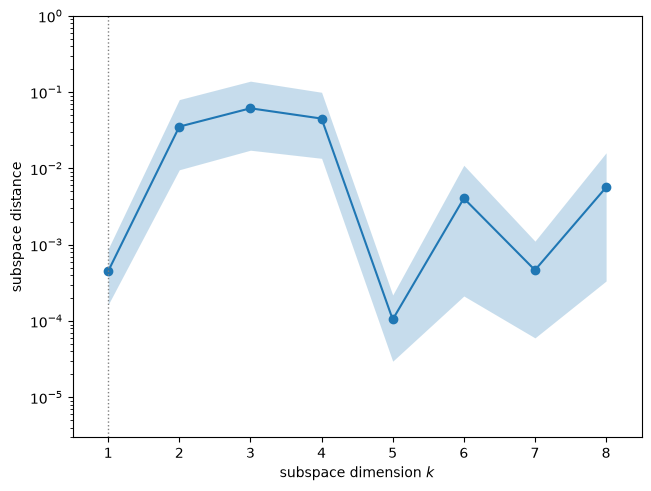

In [11]:
sub = subs[2]
display(ac.plotting.plot_eigenvalues(sub)[0])
display(ac.plotting.plot_subspace_errors(sub)[0])

For $A_{sa}$, $\lambda_1 = 0.3056$ and $\lambda_2 = 6.494\times10^{-5}$ ($\lambda_1/\lambda_2 = 4705$); the rule picks $n = 1$, and the mean bootstrap subspace distance is $4.5\times10^{-4}$ for $n = 1$ and $3.5\times10^{-2}$ for $n = 2$.

w1 ratio P_other/F_s = -3.282; ratio of the log-slopes at the means = -3.283


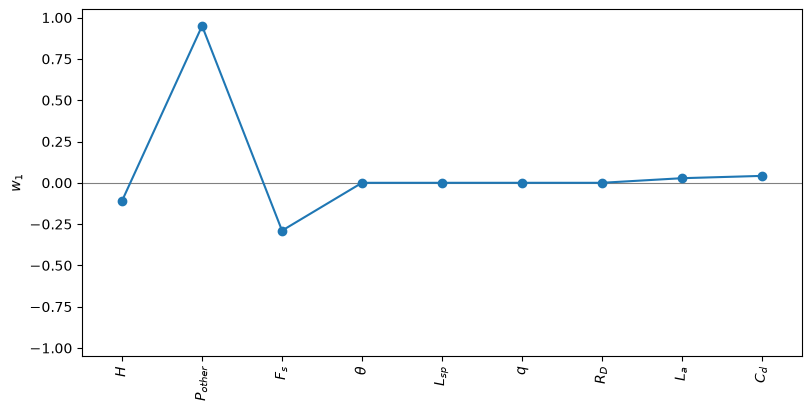

In [12]:
# A_sa = P_sa(P_tot, H) / P_EOL(F_s): log A_sa has normalized slopes sd/P_tot for P_other and -sd/F_s for F_s
r = (fm.SD[1] / F[:, 1].mean()) / (-fm.SD[2] / fm.MEAN[2])
print(f'w1 ratio P_other/F_s = {sub.W[1, 0] / sub.W[2, 0]:.3f}; ratio of the log-slopes at the means = {r:.3f}')
fig, _ = ac.plotting.plot_eigenvectors(sub, indices=[0], labels=labels, interval='percentile', figsize=(8, 4))
fig

The first eigenvector combines $P_{other}$ (+0.950) and the solar flux $F_s$ (−0.289), with smaller weights on $H$ (−0.108) and $C_d$ (+0.042). Since $A_{sa} = P_{sa}(P_{tot}, H)/P_{EOL}(F_s)$ is proportional to $P_{tot}/F_s$, the ratio of the $P_{other}$ and $F_s$ components should be the ratio of the log-slopes $(\sigma_{P}/\bar P_{tot})/(-\sigma_{F_s}/\bar F_s)$: $-3.282$ from $\mathbf w_1$ against $-3.283$ from the means. Altitude enters through the fraction of the orbit spent in eclipse.

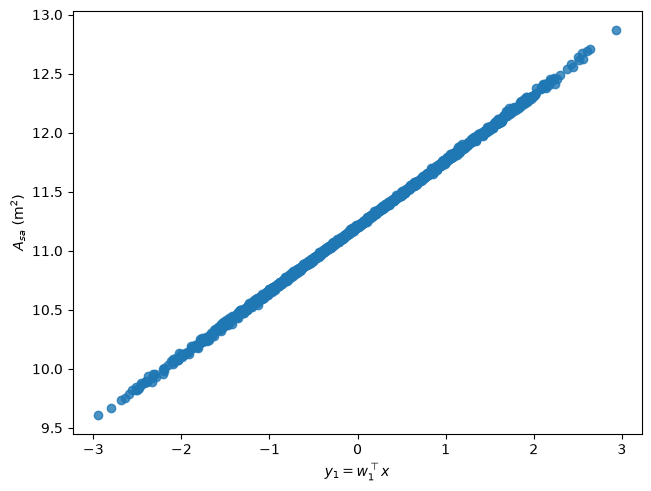

In [13]:
fig, _ = ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, 2], dims=1, qoi_label=qoi_labels[2])
fig

The summary plot of $A_{sa}$ against $y_1$ is a thin, nearly straight band; a quadratic in $y_1$ has a leave-one-out $R^2$ of 0.99969.

### Surrogates on the active variables

We fit polynomial surrogates $g(\mathbf W_1^T\mathbf x)$ on the active variables and report the leave-one-out $R^2$: for each output a one-dimensional fit, and for $\tau_{tot}$ also a two-dimensional one.

tau_tot: n = 1, degree 1: LOO R^2 = 0.97048
tau_tot: n = 1, degree 2: LOO R^2 = 0.98313
tau_tot: n = 1, degree 3: LOO R^2 = 0.98312
tau_tot: n = 2, degree 1: LOO R^2 = 0.97040
tau_tot: n = 2, degree 2: LOO R^2 = 0.99963
tau_tot: n = 2, degree 3: LOO R^2 = 0.99962
P_tot: n = 1, degree 1: LOO R^2 = 0.99992
P_tot: n = 1, degree 2: LOO R^2 = 0.99992
P_tot: n = 1, degree 3: LOO R^2 = 0.99992
A_sa: n = 1, degree 1: LOO R^2 = 0.99965
A_sa: n = 1, degree 2: LOO R^2 = 0.99969
A_sa: n = 1, degree 3: LOO R^2 = 0.99969


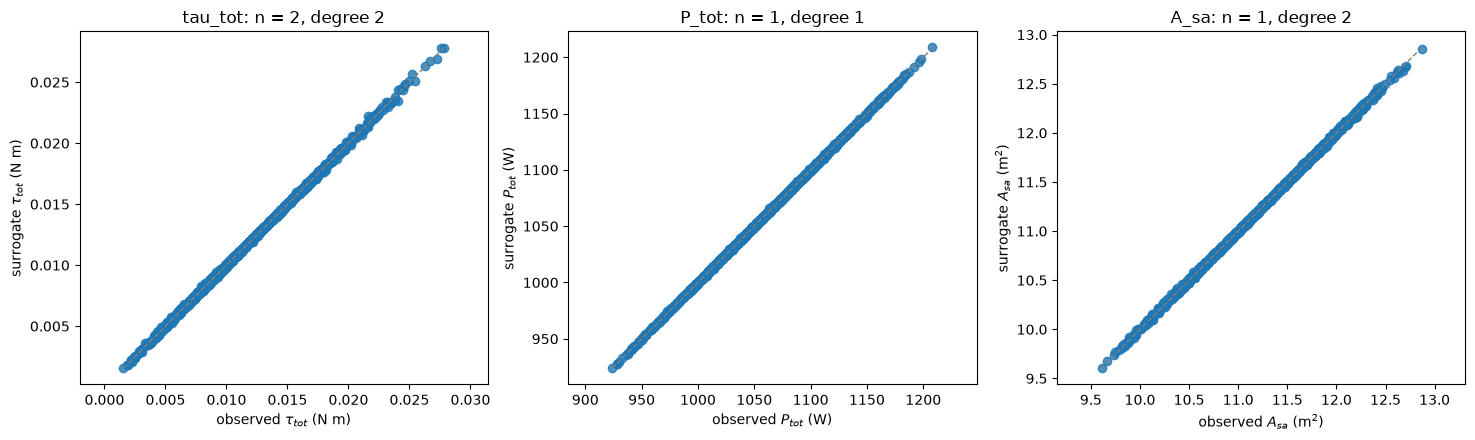

In [14]:
fits = {}
for i, q in enumerate(fm.QOI_NAMES):
    for n in ([1, 2] if i == 0 else [1]):
        for deg in [1, 2, 3]:
            s = ac.fit_surrogate(X=X, f=F[:, i], space=space, subspace=ac.with_dimension(subs[i], n),
                                 kind='poly', degree=deg)
            fits[q, n, deg] = s
            print(f'{q}: n = {n}, degree {deg}: LOO R^2 = {s.loo_r_squared:.5f}')
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (i, n, deg) in zip(axes, [(0, 2, 2), (1, 1, 1), (2, 1, 2)]):
    ac.plotting.plot_surrogate_fit(fits[fm.QOI_NAMES[i], n, deg], X=X, f=F[:, i], qoi_label=qoi_labels[i], ax=ax)
    ax.set_title(f'{fm.QOI_NAMES[i]}: n = {n}, degree {deg}')
fig.tight_layout()
plt.close(fig)
fig

One active variable is enough for $P_{tot}$ (leave-one-out $R^2$ = 0.99992 already for a linear fit) and $A_{sa}$ (0.99965 linear, 0.99969 quadratic). For $\tau_{tot}$, one active variable gives at best 0.98313 (quadratic); two active variables with a quadratic give 0.99963, while a linear fit in two variables is no better than in one (0.97040), because the second direction enters through the curvature of $L_aC_d$.

### Sensitivity to the standard deviation of $q$

The paper's Table 2 gives the reflectance factor $q$ a standard deviation of 1; the OpenTURNS use case has 0.1. We redraw 2000 samples with sd 0.1 (same bounds, seed `SEED`), recompute the gradients (a fraction of a second), and compare the leading eigenvectors.

In [15]:
sd_alt = fm.SD.copy()
sd_alt[5] = 0.1
X_alt = fm.sample(2000, SEED, sd=sd_alt)
F_alt, G_alt = fm.qoi(X_alt), fm.grad(X_alt)
space_alt = ac.Gaussian(fm.MEAN, sd_alt**2, names=list(fm.NAMES))
for i, q in enumerate(fm.QOI_NAMES):
    s_alt = ac.active_subspace(space=space_alt, X=X_alt, f=F_alt[:, i], grads=G_alt[:, i])
    lam = s_alt.eigenvalues
    print(f'{q}: q sd 0.1 gives lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, n = {s_alt.n}; '
          f'|w1(sd 1) . w1(sd 0.1)| = {abs(subs[i].W[:, 0] @ s_alt.W[:, 0]):.5f}; '
          f'|w1 component of q| = {abs(subs[i].W[5, 0]):.1e} (sd 1), {abs(s_alt.W[5, 0]):.1e} (sd 0.1)')

tau_tot: q sd 0.1 gives lambda_1/lambda_2 = 36.3, n = 1; |w1(sd 1) . w1(sd 0.1)| = 1.00000; |w1 component of q| = 5.7e-04 (sd 1), 5.7e-05 (sd 0.1)
P_tot: q sd 0.1 gives lambda_1/lambda_2 = 12162.2, n = 1; |w1(sd 1) . w1(sd 0.1)| = 1.00000; |w1 component of q| = 3.3e-05 (sd 1), 3.3e-06 (sd 0.1)
A_sa: q sd 0.1 gives lambda_1/lambda_2 = 4705.1, n = 1; |w1(sd 1) . w1(sd 0.1)| = 1.00000; |w1 component of q| = 3.2e-05 (sd 1), 3.2e-06 (sd 0.1)


The standard deviation of $q$ makes no difference: with 0.1 instead of 1, the first eigenvectors agree to $|\mathbf w_1\cdot\mathbf w_1'| = 1.00000$ for all three outputs, and the eigenvalue ratios are 36.3, 12162.2 and 4705.1. The component of $q$ in $\mathbf w_1$ is at most $5.7\times10^{-4}$ (for $\tau_{tot}$, sd 1). The reflectance factor enters only through the solar radiation torque $\tau_{sp}$, which is small against the aerodynamic torque. (The two sample sets come from the same seed, so they share every column except $q$.)

### Comparison with the paper

The paper reports output distributions (Figs. 11–14), not active subspaces. We compare the modes of kernel density estimates of our outputs with the peaks read from its figures (approximate, read by eye from the published PDF). The paper's distributions are untruncated normals and its benchmark (SOFPI) used about 200,000 samples; ours are truncated at $\pm 3$ sd and use 2000.

In [16]:
P_ACS = F[:, 1] - X[:, 1]
cols = {'P_ACS (W), Fig. 11': (P_ACS, '~67'), 'P_tot (W), Fig. 12': (F[:, 1], '~1070'),
        'A_sa (m^2), Fig. 13': (F[:, 2], '~12.2'), 'tau_tot (N m), Fig. 14': (F[:, 0], '~0.011')}
print(f"{'quantity':24s} {'paper peak':>11s} {'KDE mode':>10s} {'mean':>10s} {'sd':>9s}")
for k, (v, paper) in cols.items():
    grid = np.linspace(v.min(), v.max(), 2001)
    mode = grid[np.argmax(stats.gaussian_kde(v)(grid))]
    print(f'{k:24s} {paper:>11s} {mode:10.4g} {v.mean():10.4g} {v.std():9.3g}')
F_ot = fm.qoi(fm.MEAN, omega_max=6000., mu=398600.4418e9)[0]
print(f'at the mean inputs with the OpenTURNS conventions (omega_max = 6000 rad/s, mu = 3.986004418e14): '
      f'tau_tot = {F_ot[0]:.6g}, P_tot = {F_ot[1]:.6g}, A_sa = {F_ot[2]:.6g}')

quantity                  paper peak   KDE mode       mean        sd
P_ACS (W), Fig. 11               ~67      66.46      67.32      2.64
P_tot (W), Fig. 12             ~1070       1052       1066      49.5


A_sa (m^2), Fig. 13            ~12.2       11.1      11.19     0.544


tau_tot (N m), Fig. 14        ~0.011    0.01028    0.01165    0.0042
at the mean inputs with the OpenTURNS conventions (omega_max = 6000 rad/s, mu = 3.986004418e14): tau_tot = 0.0116597, P_tot = 1129.96, A_sa = 11.8626


| quantity | paper value | notebook value |
|---|---|---|
| $P_{ACS}$ peak (W) | ~67 (Fig. 11) | mean 67.32, KDE mode 66.46 |
| $P_{tot}$ peak (W) | ~1070 (Fig. 12) | mean 1066, KDE mode 1052 |
| $A_{sa}$ peak (m²) | ~12.2 (Fig. 13) | mean 11.19, KDE mode 11.1 |
| $\tau_{tot}$ peak (N m) | ~0.011 (Fig. 14) | mean 0.01165, KDE mode 0.01028 |
| active subspace dimension $n$ | not reported | 1 for each output (2 useful for $\tau_{tot}$) |
| $\lambda_1/\lambda_2$ ($\tau_{tot}$, $P_{tot}$, $A_{sa}$) | not reported | 36.3, 12162.0, 4705.1 |
| leading input(s) of $\mathbf w_1$ | not reported | $C_d$, $L_a$; $P_{other}$; $P_{other}$, $F_s$ |
| global sensitivity indices | not reported | not computed |

(The KDE mode of $P_{tot}$ is a noisy estimate of the peak of a nearly normal distribution from 2000 samples; the mean is the better comparison.)

The coupling variable and two of the outputs agree with the paper's figures: the mean of $P_{ACS}$ is 67.32 W against a peak near 67 W in Fig. 11, the mean of $P_{tot}$ is 1066 W against a peak near 1070 W in Fig. 12, and the KDE mode of $\tau_{tot}$ is 0.01028 N m against a peak near 0.011 N m in Fig. 14. The solar array area does not: our mean is 11.19 m² and our mode 11.1 m², against a peak near 12.2 m² in Fig. 13, about 9% higher. Since our $P_{tot}$ matches Fig. 12 and $A_{sa}$ depends on the inputs only through $P_{tot}$, $H$ and $F_s$, the paper's Figs. 12 and 13 appear inconsistent with its own Eqs. (24)–(26) and Table 1: some constant or step of the power calculation must differ from what is printed, and we could not identify which (see `DATA.md`). The OpenTURNS implementation [[4]](#refs) gives $A_{sa} = 11.8626$ m² at the mean inputs, but only because it uses $\omega_{max} = 6000$ rad/s, which roughly doubles $P_{ACS}$; our model with its conventions reproduces its three outputs at the mean inputs (0.0116597, 1129.96, 11.8626, against 0.0116597, 1129.96 and 11.8626 from OpenTURNS 1.27; `DATA.md`). The paper reports no active subspace or sensitivity results, so there is nothing to compare for $\lambda$ or $\mathbf w$.

In [17]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 8 s


<a id="refs"></a>
### References

[1] S. Sankararaman and S. Mahadevan, Likelihood-based approach to multidisciplinary analysis under uncertainty, *Journal of Mechanical Design* 134(3):031008, 2012. [doi:10.1115/1.4005619](https://doi.org/10.1115/1.4005619)

[2] J. R. Wertz and W. J. Larson (eds.), *Space Mission Analysis and Design*, 3rd ed., Microcosm, Torrance, CA, 1999.

[3] S. Ferson, W. Tucker, C. Paredis, Y. Bulgak and V. Kreinovich, Accounting for epistemic and aleatory uncertainty in early system design, NASA SBIR technical report, 2009.

[4] OpenTURNS, Fire Satellite use case (`openturns.usecases.fire_satellite`), <https://openturns.github.io/openturns/latest/usecases/use_case_fire_satellite.html>.

[5] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

[6] J. R. R. A. Martins, P. Sturdza and J. J. Alonso, The complex-step derivative approximation, *ACM Transactions on Mathematical Software* 29(3):245–262, 2003. [doi:10.1145/838250.838251](https://doi.org/10.1145/838250.838251)

### Acknowledgments

The paper [1] acknowledges support from NASA Langley Research Center (Contract No. NNX08AF56A1; Technical Monitor: Lawrence Green) and NASA Jet Propulsion Laboratory (Contract No. RSA 1400821; Principal Investigator: Dr. Lee Peterson).